# Super-Convergence: CIFAR-10 / ResNet-20

## 1. Библиотеки и параметры

In [1]:
import copy
import json
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(2026)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(4)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.allow_tf32 = True
torch.backends.cuda.matmul.allow_tf32 = True
results_dir = Path('results')
results_dir.mkdir(exist_ok=True)
torch.hub.set_dir(str(Path('.cache/torch').resolve()))

batch_size = 256
num_workers = 2
epochs = 60
seeds = [17, 42]
reuse_completed_runs = True
target_accuracy = 90.0
weight_decay = 1e-4
momentum = 0.9
baseline_lr = 0.1
model_commit = '786c16252c0fc58ee9adac063f8337cc4a7a497a'
print('Device:', device)
if device.type == 'cuda':
    print(torch.cuda.get_device_name())
print('PyTorch:', torch.__version__, 'torchvision:', torchvision.__version__)

Device: cuda
NVIDIA GeForce RTX 5060 Ti
PyTorch: 2.9.1+cu128 torchvision: 0.24.1+cu128


## 2. CIFAR-10: train / validation / test

In [2]:
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
datasets.CIFAR10.url = ('https://huggingface.co/datasets/MIT-OL-AI-D/cifar-10-python/'
                       'resolve/a48007227f9e2cd0af96175f4afb5ac4965e261b/cifar-10-python.tar.gz')
train_dataset = datasets.CIFAR10('.cache/data', train=True, download=True,
                                 transform=train_transform)
validation_dataset = datasets.CIFAR10('.cache/data', train=True, download=False,
                                      transform=test_transform)
test_dataset = datasets.CIFAR10('.cache/data', train=False, download=True,
                                transform=test_transform)
split_generator = np.random.default_rng(2026)
train_indices = []
validation_indices = []
labels = np.array(train_dataset.targets)
for label in range(10):
    indices = split_generator.permutation(np.flatnonzero(labels == label))
    validation_indices.extend(indices[:500].tolist())
    train_indices.extend(indices[500:].tolist())
train_dataset = Subset(train_dataset, train_indices)
validation_dataset = Subset(validation_dataset, validation_indices)
assert not set(train_indices).intersection(validation_indices)
validation_loader = DataLoader(validation_dataset, batch_size=512, shuffle=False,
                               num_workers=0, pin_memory=device.type == 'cuda')
test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False,
                         num_workers=0, pin_memory=device.type == 'cuda')
pd.DataFrame({'index': train_indices, 'split': 'train'}).to_csv(
    results_dir / 'train_split.csv', index=False)
pd.DataFrame({'index': validation_indices, 'split': 'validation'}).to_csv(
    results_dir / 'validation_split.csv', index=False)
print('Train:', len(train_dataset), 'Validation:', len(validation_dataset),
      'Test:', len(test_dataset))

Train: 45000 Validation: 5000 Test: 10000


## 3. Готовая CIFAR ResNet-20

In [3]:
model_template = torch.hub.load(
    'chenyaofo/pytorch-cifar-models:' + model_commit,
    'cifar10_resnet20', pretrained=False, trust_repo=True, skip_validation=True, verbose=False)

def make_model(seed):
    set_seed(seed)
    model = copy.deepcopy(model_template)
    for layer in model.modules():
        if isinstance(layer, (nn.Conv2d, nn.BatchNorm2d, nn.Linear)):
            layer.reset_parameters()
        if isinstance(layer, nn.Conv2d):
            nn.init.kaiming_normal_(layer.weight, mode='fan_out', nonlinearity='relu')
        if isinstance(layer, nn.BatchNorm2d):
            layer.momentum = 0.05
    return model.to(device, memory_format=torch.channels_last)

model = make_model(2026)
assert model.conv1.kernel_size == (3, 3) and model.conv1.stride == (1, 1)
assert [len(model.layer1), len(model.layer2), len(model.layer3)] == [3, 3, 3]
assert [model.layer1[0].conv1.out_channels, model.layer2[0].conv1.out_channels,
        model.layer3[0].conv1.out_channels] == [16, 32, 64]
assert not any(isinstance(layer, nn.MaxPool2d) for layer in model.modules())
parameter_count = sum(parameter.numel() for parameter in model.parameters())
assert parameter_count == 272474
print('CIFAR ResNet-20: 3 x 3 BasicBlock, channels 16/32/64, parameters:', parameter_count)
print('Shortcut: 1x1 projection; BatchNorm momentum: 0.05')

def evaluate(model, loader):
    model.eval()
    total_loss = torch.zeros((), device=device)
    correct = torch.zeros((), device=device)
    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(device, memory_format=torch.channels_last, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            outputs = model(images)
            total_loss += nn.functional.cross_entropy(outputs, labels, reduction='sum')
            correct += (outputs.argmax(1) == labels).sum()
    return total_loss.item() / len(loader.dataset), 100 * correct.item() / len(loader.dataset)

CIFAR ResNet-20: 3 x 3 BasicBlock, channels 16/32/64, parameters: 272474
Shortcut: 1x1 projection; BatchNorm momentum: 0.05


## 4. Проверка обучения и скорости

In [4]:
set_seed(2026)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                          num_workers=num_workers, pin_memory=device.type == 'cuda',
                          generator=torch.Generator().manual_seed(2026))
model = make_model(2026)
optimizer = torch.optim.SGD(model.parameters(), lr=baseline_lr, momentum=momentum,
                            weight_decay=weight_decay)
smoke_losses = []
started = time.perf_counter()
model.train()
for step, (images, labels) in enumerate(train_loader):
    images = images.to(device, memory_format=torch.channels_last, non_blocking=True)
    labels = labels.to(device, non_blocking=True)
    optimizer.zero_grad(set_to_none=True)
    loss = nn.functional.cross_entropy(model(images), labels)
    loss.backward()
    optimizer.step()
    smoke_losses.append(loss.item())
    if step == 31:
        break
smoke_seconds = time.perf_counter() - started
assert np.isfinite(smoke_losses).all()
pd.DataFrame({'step': range(1, 33), 'train_loss': smoke_losses}).to_csv(
    results_dir / 'smoke.csv', index=False)
print(f'32 optimizer steps: {smoke_seconds:.2f} s; last loss: {smoke_losses[-1]:.4f}')
print(f'Approximate training epoch: {smoke_seconds / 32 * len(train_loader):.1f} s')

32 optimizer steps: 7.78 s; last loss: 1.8398
Approximate training epoch: 42.8 s


## 5. LR Range Test: выбор по validation

LR range 1: lr=0.307, val=37.38%


LR range 2: lr=0.607, val=50.16%


LR range 3: lr=0.906, val=39.02%


LR range 4: lr=1.205, val=55.74%


LR range 5: lr=1.504, val=63.70%


LR range 6: lr=1.803, val=57.98%


LR range 7: lr=2.102, val=44.10%


LR range 8: lr=2.402, val=58.78%


LR range 9: lr=2.701, val=41.32%


LR range 10: lr=3.000, val=47.64%
Selected max_lr: 1.44; range test: 112.2 s


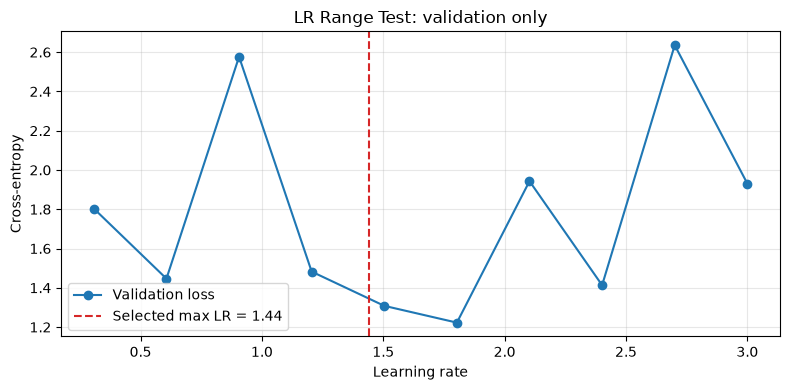

In [5]:
model = make_model(2026)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                          num_workers=num_workers, persistent_workers=num_workers > 0,
                          pin_memory=device.type == 'cuda',
                          generator=torch.Generator().manual_seed(2026))
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=momentum,
                            weight_decay=weight_decay)
range_epochs = 10
range_steps = range_epochs * len(train_loader)
range_history = []
range_batches = []
range_started = time.perf_counter()
for epoch in range(range_epochs):
    model.train()
    train_loss = 0.0
    seen = 0
    for images, labels in train_loader:
        learning_rate = 0.01 + (3.0 - 0.01) * len(range_batches) / (range_steps - 1)
        optimizer.param_groups[0]['lr'] = learning_rate
        images = images.to(device, memory_format=torch.channels_last, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        loss = nn.functional.cross_entropy(model(images), labels)
        if not torch.isfinite(loss) or loss.item() > 20:
            break
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * len(labels)
        seen += len(labels)
        range_batches.append({'step': len(range_batches) + 1, 'lr': learning_rate,
                              'train_loss': loss.item()})
    validation_loss, validation_accuracy = evaluate(model, validation_loader)
    range_history.append({'epoch': epoch + 1, 'step': len(range_batches),
                          'lr': learning_rate, 'train_loss': train_loss / max(seen, 1),
                          'validation_loss': validation_loss,
                          'validation_accuracy': validation_accuracy})
    print(f'LR range {epoch + 1}: lr={learning_rate:.3f}, val={validation_accuracy:.2f}%')
    if seen < len(train_dataset):
        break
range_seconds = time.perf_counter() - range_started
range_frame = pd.DataFrame(range_history)
range_frame.to_csv(results_dir / 'lr_range.csv', index=False)
pd.DataFrame(range_batches).to_csv(results_dir / 'lr_range_batches.csv', index=False)
best_range = range_frame.loc[range_frame.validation_loss.idxmin()]
max_lr = float(np.clip(round(0.8 * best_range.lr, 2), 0.1, 3.0))
print(f'Selected max_lr: {max_lr:.2f}; range test: {range_seconds:.1f} s')
plt.figure(figsize=(8, 4))
plt.plot(range_frame.lr, range_frame.validation_loss, 'o-', label='Validation loss')
plt.axvline(max_lr, color='tab:red', linestyle='--', label=f'Selected max LR = {max_lr}')
plt.xlabel('Learning rate')
plt.ylabel('Cross-entropy')
plt.title('LR Range Test: validation only')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(results_dir / 'lr_range.png', dpi=180)
plt.show()

## 6. SGD + MultiStepLR и SGD + 1cycle

In [6]:
runs = []
for seed in seeds:
    runs.append({'method': 'Baseline', 'seed': seed, 'epochs': epochs})
    runs.append({'method': '1cycle', 'seed': seed, 'epochs': epochs})
runs.append({'method': 'Baseline-long', 'seed': seeds[0], 'epochs': 2 * epochs})
settings = {
    'device': str(device), 'gpu': torch.cuda.get_device_name() if device.type == 'cuda' else None,
    'torch': torch.__version__, 'torchvision': torchvision.__version__,
    'model_commit': model_commit, 'parameters': parameter_count,
    'batch_size': batch_size, 'train_size': len(train_dataset),
    'validation_size': len(validation_dataset), 'test_size': len(test_dataset),
    'seeds': seeds, 'epochs': epochs, 'target_accuracy': target_accuracy,
    'baseline_lr': baseline_lr, 'max_lr': max_lr, 'momentum': momentum,
    'weight_decay': weight_decay, 'pct_start': 0.45, 'three_phase': True,
    'anneal_strategy': 'linear', 'div_factor': 10, 'final_div_factor': 1000,
    'range_seconds': range_seconds, 'runs': runs,
}
history = []
learning_rates = []
completed_runs = []
if reuse_completed_runs and all((results_dir / name).exists() for name in
                                ['settings.json', 'metrics.csv', 'learning_rates.csv']):
    saved_settings = json.loads((results_dir / 'settings.json').read_text())
    if all(saved_settings.get(key) == value for key, value in settings.items()
           if key != 'range_seconds'):
        saved_metrics = pd.read_csv(results_dir / 'metrics.csv')
        saved_rates = pd.read_csv(results_dir / 'learning_rates.csv')
        for run in runs:
            rows = saved_metrics[(saved_metrics.method == run['method']) &
                                 (saved_metrics.seed == run['seed'])]
            rates = saved_rates[(saved_rates.method == run['method']) &
                                (saved_rates.seed == run['seed'])]
            checkpoint = results_dir / (run['method'].lower() +
                                        f"_seed{run['seed']}_final.pt")
            expected_steps = run['epochs'] * len(train_loader)
            if len(rows) == run['epochs'] and len(rates) == expected_steps and checkpoint.exists():
                history.extend(rows.to_dict('records'))
                learning_rates.extend(rates.to_dict('records'))
                completed_runs.append((run['method'], run['seed'], run['epochs']))
(results_dir / 'settings.json').write_text(json.dumps(settings, indent=2), encoding='utf-8')
for run in runs:
    seed, method, run_epochs = run['seed'], run['method'], run['epochs']
    if (method, seed, run_epochs) in completed_runs:
        print(f'Loaded completed run: {method}, seed={seed}, epochs={run_epochs}')
        continue
    initial_model = make_model(seed)
    model = copy.deepcopy(initial_model)
    assert all(torch.equal(value, initial_model.state_dict()[name])
               for name, value in model.state_dict().items())
    set_seed(seed)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                              num_workers=num_workers, persistent_workers=num_workers > 0,
                              pin_memory=device.type == 'cuda',
                              generator=torch.Generator().manual_seed(seed))
    optimizer = torch.optim.SGD(model.parameters(), lr=baseline_lr,
                                momentum=momentum, weight_decay=weight_decay)
    if method == '1cycle':
        scheduler = torch.optim.lr_scheduler.OneCycleLR(
            optimizer, max_lr=max_lr, epochs=run_epochs, steps_per_epoch=len(train_loader),
            pct_start=0.45, anneal_strategy='linear', three_phase=True,
            div_factor=10, final_div_factor=1000, cycle_momentum=False)
    else:
        scheduler = torch.optim.lr_scheduler.MultiStepLR(
            optimizer, milestones=[int(0.625 * run_epochs), int(0.875 * run_epochs)], gamma=0.1)
    train_losses = []
    test_accuracies = []
    optimizer_steps = 0
    training_seconds = 0.0
    if device.type == 'cuda':
        torch.cuda.synchronize()
    run_started = time.perf_counter()
    for epoch in range(1, run_epochs + 1):
        epoch_started = time.perf_counter()
        model.train()
        total_loss = torch.zeros((), device=device)
        for images, labels in train_loader:
            images = images.to(device, memory_format=torch.channels_last, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            loss = nn.functional.cross_entropy(model(images), labels)
            loss.backward()
            learning_rates.append({'method': method, 'seed': seed, 'step': optimizer_steps + 1,
                                   'lr': optimizer.param_groups[0]['lr']})
            optimizer.step()
            optimizer_steps += 1
            if method == '1cycle':
                scheduler.step()
            total_loss += loss.detach() * len(labels)
        if method != '1cycle':
            scheduler.step()
        train_losses.append(total_loss.item() / len(train_dataset))
        training_seconds += time.perf_counter() - epoch_started
        validation_loss, validation_accuracy = evaluate(model, validation_loader)
        test_loss, test_accuracy = evaluate(model, test_loader)
        test_accuracies.append(test_accuracy)
        assert np.isfinite([train_losses[-1], validation_loss, test_loss]).all()
        history.append({'method': method, 'seed': seed, 'epoch': epoch,
                        'step': optimizer_steps, 'train_loss': train_losses[-1],
                        'validation_loss': validation_loss, 'validation_accuracy': validation_accuracy,
                        'test_loss': test_loss, 'test_accuracy': test_accuracy,
                        'training_seconds': training_seconds,
                        'wall_seconds': time.perf_counter() - run_started})
        pd.DataFrame(history).to_csv(results_dir / 'metrics.csv', index=False)
        print(f'{method} seed={seed} epoch={epoch}/{run_epochs}: '
              f'loss={train_losses[-1]:.4f}, test={test_accuracy:.2f}%, '
              f'train={training_seconds:.1f}s', flush=True)
    torch.save(model.state_dict(), results_dir / f'{method.lower()}_seed{seed}_final.pt')
    pd.DataFrame(learning_rates).to_csv(results_dir / 'learning_rates.csv', index=False)
metrics = pd.DataFrame(history)
learning_rates = pd.DataFrame(learning_rates)

Loaded completed run: Baseline, seed=17, epochs=60
Loaded completed run: 1cycle, seed=17, epochs=60
Loaded completed run: Baseline, seed=42, epochs=60
Loaded completed run: 1cycle, seed=42, epochs=60


Baseline-long seed=17 epoch=1/120: loss=1.6596, test=39.53%, train=15.3s


Baseline-long seed=17 epoch=2/120: loss=1.1480, test=51.07%, train=25.7s


Baseline-long seed=17 epoch=3/120: loss=0.9370, test=58.81%, train=36.2s


Baseline-long seed=17 epoch=4/120: loss=0.8100, test=66.02%, train=46.6s


...

Baseline-long seed=17 epoch=116/120: loss=0.0283, test=90.32%, train=1197.2s


Baseline-long seed=17 epoch=117/120: loss=0.0296, test=90.35%, train=1207.6s


Baseline-long seed=17 epoch=118/120: loss=0.0269, test=90.35%, train=1218.0s


Baseline-long seed=17 epoch=119/120: loss=0.0285, test=90.38%, train=1228.4s


Baseline-long seed=17 epoch=120/120: loss=0.0284, test=90.46%, train=1238.8s


## 7. Графики реальных экспериментов

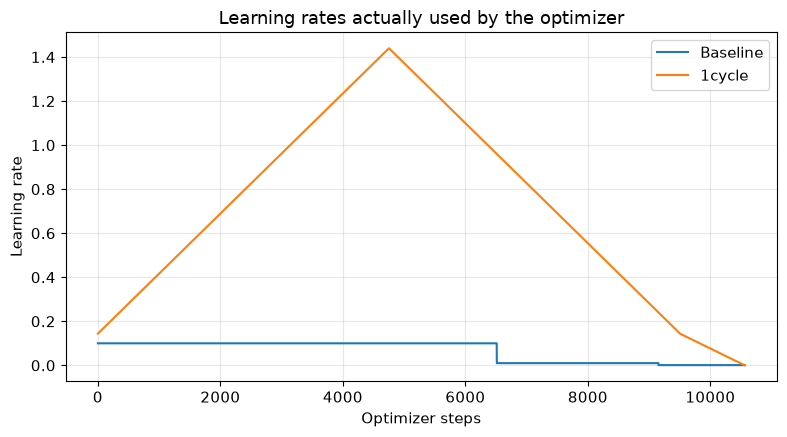

In [7]:
plt.rcParams.update({'figure.figsize': (8, 4.5), 'font.size': 11})
main_metrics = metrics[metrics.method.isin(['Baseline', '1cycle'])]
mean_metrics = main_metrics.groupby(['method', 'epoch'], as_index=False).mean(numeric_only=True)
std_metrics = main_metrics.groupby(['method', 'epoch'], as_index=False).std(numeric_only=True)
plt.figure()
for method in ['Baseline', '1cycle']:
    rows = learning_rates[(learning_rates.method == method) & (learning_rates.seed == seeds[0])]
    plt.plot(rows.step, rows.lr, label=method)
plt.xlabel('Optimizer steps')
plt.ylabel('Learning rate')
plt.title('Learning rates actually used by the optimizer')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(results_dir / 'learning_rates.png', dpi=180)
plt.show()

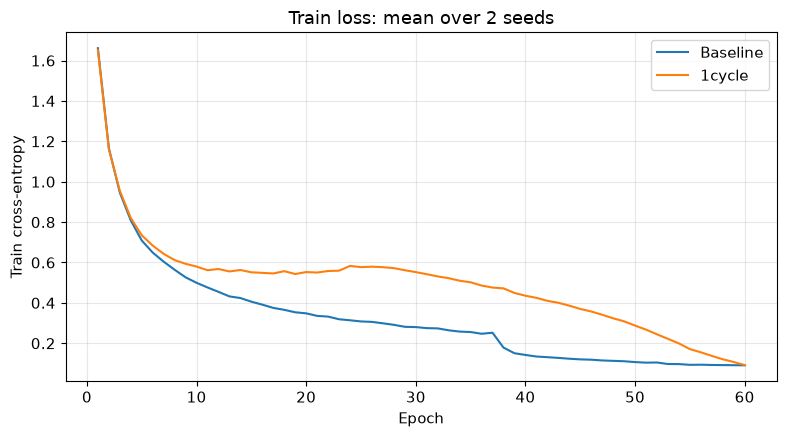

In [8]:
plt.figure()
for method in ['Baseline', '1cycle']:
    rows = mean_metrics[mean_metrics.method == method]
    plt.plot(rows.epoch, rows.train_loss, label=method)
plt.xlabel('Epoch')
plt.ylabel('Train cross-entropy')
plt.title(f'Train loss: mean over {len(seeds)} seeds')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(results_dir / 'train_loss.png', dpi=180)
plt.show()

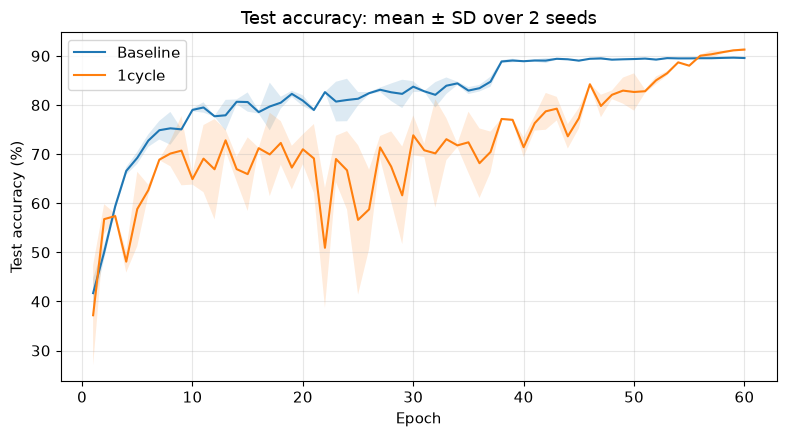

In [9]:
plt.figure()
for method in ['Baseline', '1cycle']:
    rows = mean_metrics[mean_metrics.method == method]
    spread = std_metrics[std_metrics.method == method].test_accuracy.fillna(0)
    plt.plot(rows.epoch, rows.test_accuracy, label=method)
    plt.fill_between(rows.epoch, rows.test_accuracy - spread,
                     rows.test_accuracy + spread, alpha=0.15)
plt.xlabel('Epoch')
plt.ylabel('Test accuracy (%)')
plt.title(f'Test accuracy: mean ± SD over {len(seeds)} seeds')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(results_dir / 'test_accuracy.png', dpi=180)
plt.show()

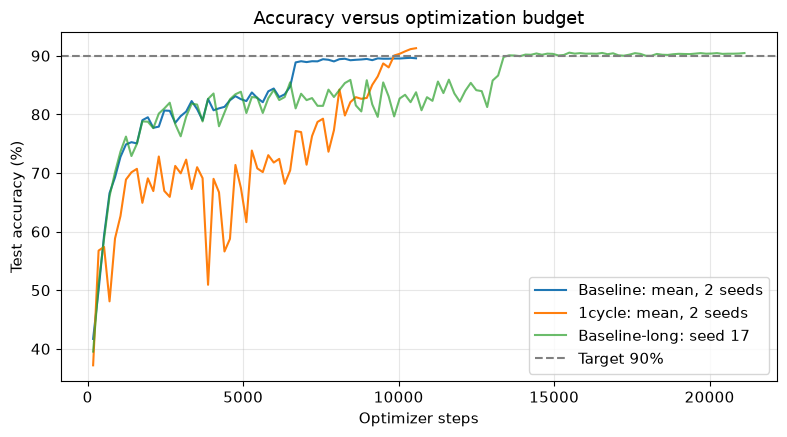

In [10]:
plt.figure()
for method in ['Baseline', '1cycle']:
    rows = mean_metrics[mean_metrics.method == method]
    plt.plot(rows.step, rows.test_accuracy, label=f'{method}: mean, {len(seeds)} seeds')
rows = metrics[metrics.method == 'Baseline-long']
plt.plot(rows.step, rows.test_accuracy, label=f'Baseline-long: seed {seeds[0]}', alpha=0.7)
plt.axhline(target_accuracy, color='gray', linestyle='--', label=f'Target {target_accuracy:.0f}%')
plt.xlabel('Optimizer steps')
plt.ylabel('Test accuracy (%)')
plt.title('Accuracy versus optimization budget')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(results_dir / 'accuracy_steps.png', dpi=180)
plt.show()

## 8. Итоговые таблицы и проверка CSV

In [11]:
summary_rows = []
for (method, seed), rows in metrics.groupby(['method', 'seed'], sort=False):
    last = rows.iloc[-1]
    reached = rows[rows.test_accuracy >= target_accuracy]
    summary_rows.append({
        'method': method, 'seed': seed, 'epochs': int(last.epoch), 'steps': int(last.step),
        'final_accuracy': last.test_accuracy, 'best_accuracy': rows.test_accuracy.max(),
        'final_validation_accuracy': last.validation_accuracy,
        'training_seconds': last.training_seconds, 'wall_seconds': last.wall_seconds,
        'target_accuracy': target_accuracy,
        'step_to_target': int(reached.iloc[0].step) if len(reached) else np.nan,
        'train_seconds_to_target': reached.iloc[0].training_seconds if len(reached) else np.nan,
    })
summary = pd.DataFrame(summary_rows)
summary.to_csv(results_dir / 'summary.csv', index=False)
display(summary.round(3))

,method,seed,epochs,steps,final_accuracy,best_accuracy,final_validation_accuracy,training_seconds,wall_seconds,target_accuracy,step_to_target,train_seconds_to_target
0,Baseline,17,60,10560,89.68,89.76,90.34,637.959,717.034,90.0,NaN,NaN
1,1cycle,17,60,10560,91.49,91.49,91.94,637.562,716.183,90.0,9856.0,595.426
2,Baseline,42,60,10560,89.46,89.59,90.44,615.463,691.076,90.0,NaN,NaN
3,1cycle,42,60,10560,91.09,91.09,92.00,642.243,719.079,90.0,10208.0,620.525
4,Baseline-long,17,120,21120,90.46,90.53,90.20,1238.807,1391.890,90.0,13552.0,796.437


In [12]:
statistics = summary.groupby('method', sort=False)[
    ['final_accuracy', 'best_accuracy', 'training_seconds', 'step_to_target']].agg(['mean', 'std', 'count'])
statistics.to_csv(results_dir / 'summary_statistics.csv')
display(statistics.round(3))
paired = summary[summary.method.isin(['Baseline', '1cycle'])].pivot(
    index='seed', columns='method', values='final_accuracy')
paired['difference_pp'] = paired['1cycle'] - paired['Baseline']
paired.to_csv(results_dir / 'paired_differences.csv')
display(paired.round(3))
saved_metrics = pd.read_csv(results_dir / 'metrics.csv')
saved_rates = pd.read_csv(results_dir / 'learning_rates.csv')
pd.testing.assert_frame_equal(metrics, saved_metrics, check_dtype=False)
for row in summary.itertuples():
    selected = saved_metrics[(saved_metrics.method == row.method) & (saved_metrics.seed == row.seed)]
    rates = saved_rates[(saved_rates.method == row.method) & (saved_rates.seed == row.seed)]
    assert len(selected) == row.epochs and len(rates) == row.steps
    assert np.isclose(selected.iloc[-1].test_accuracy, row.final_accuracy)
    assert np.isclose(selected.test_accuracy.max(), row.best_accuracy)
    assert rates.step.tolist() == list(range(1, row.steps + 1))
    assert (rates.lr > 0).all()
assert summary[summary.method.isin(['Baseline', '1cycle'])].steps.nunique() == 1
print('CSV verified. Paired difference, percentage points:')
print(paired.difference_pp.agg(['mean', 'std']))

final_accuracy              best_accuracy               \
                        mean    std count          mean    std count   
method                                                                 
Baseline               89.57  0.156     2        89.675  0.120     2   
1cycle                 91.29  0.283     2        91.290  0.283     2   
Baseline-long          90.46    NaN     1        90.530    NaN     1   

              training_seconds               step_to_target                 
                          mean     std count           mean      std count  
method                                                                      
Baseline               626.711  15.907     2            NaN      NaN     0  
1cycle                 639.903   3.310     2        10032.0  248.902     2  
Baseline-long         1238.807     NaN     1        13552.0      NaN     1

method,1cycle,Baseline,difference_pp
seed,,,
17,91.49,89.68,1.81
42,91.09,89.46,1.63


CSV verified. Paired difference, percentage points:
mean    1.720000
std     0.127279
Name: difference_pp, dtype: float64
